# 07 · Sales Forecasting & Time-Series Revenue Forecasting
**Customer Revenue Intelligence**, Step 9

> ⚠️ **SYNTHETIC DATA.** Input: `data/processed/customer_sales_cleaned.csv` (the Step 3 cleaned file; the brief's `customer_sales_clean.csv` is this file). Revenue = Delivered Sales, the same rule as all earlier steps.

This notebook calls the functions in `src/forecasting.py`. The individual steps are shown below; the full run also saves every table, figure and model file.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
from IPython.display import Image
import config
from src import forecasting as fc

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = fc.FIG_DIR

R = fc.run_forecasting(make_plots=True, verbose=False)      # full, reproducible pipeline
print("Selected model:", R["selection"]["family"], "-", R["selection"]["spec"], "| files:", len(R["saved"]), "| figures:", len(R["figures"]))

Selected model: Theta - Theta (seasonality auto-tested) | files: 23 | figures: 12


## 1. Load and validate the data

In [2]:
D = fc.load_sales_data()          # same function the pipeline uses
D["quality"]

,Check,Result,OK
0,Required columns present,"Order_Date, Sales, Profit, Quantity, Customer_ID, Product_ID, Category, Region",True
1,Missing values in required columns,0,True
2,Invalid (unparseable) Order_Date,0,True
3,Duplicate Order_Line_ID,0,True
4,Fully duplicated rows,0,True
5,Delivered lines with Sales <= 0,0,True
6,Delivered lines with Quantity <= 0,0,True
7,Date range,"2023-01-01 to 2025-12-31 (1,096 days)",True
8,Calendar days with no order,0,True
9,Months with no Delivered sales,0,True


- **Checks:** no invalid or missing dates, no duplicate lines, and no Delivered line with zero or negative sales.
- **Coverage:** all 1,096 days have orders, about 12 a day.

## 2. Forecasting target and design

In [3]:
pd.DataFrame([
    ("Forecasting unit", "total company revenue (Delivered Sales, Rs)"),
    ("Time frequency", "calendar month - every month has sales; 36 points support simple models + backtesting"),
    ("Historical period", f"{R['y'].index[0]:%Y-%m} to {R['y'].index[-1]:%Y-%m} ({len(R['y'])} months)"),
    ("Forecast horizon", f"{fc.HORIZON} months ({R['future']['forecast'].index[0]:%Y-%m} to {R['future']['forecast'].index[-1]:%Y-%m})"),
    ("Why 6 months", "= the horizon evaluated on validation, test and every backtest fold; 12 would exceed anything tested"),
    ("Target variable", "Revenue per month"),
], columns=["Item", "Decision"])

,Item,Decision
0,Forecasting unit,"total company revenue (Delivered Sales, Rs)"
1,Time frequency,calendar month - every month has sales; 36 points support simple models + backtesting
2,Historical period,2023-01 to 2025-12 (36 months)
3,Forecast horizon,6 months (2026-01 to 2026-06)
4,Why 6 months,"= the horizon evaluated on validation, test and every backtest fold; 12 would exceed anything tested"
5,Target variable,Revenue per month


## 3. Monthly time-series dataset

In [4]:
ts = fc.aggregate_revenue_by_period(D["delivered"])
print("Missing months:", ts.attrs["missing_periods"], "| months:", len(ts), "| revenue reconciles:",
      np.isclose(ts["Revenue"].sum(), D["delivered"]["Sales"].sum()))
ts.head(12)

Missing months: 0 | months: 36 | revenue reconciles: True


,Month,Revenue,Profit,Quantity,Orders,Customers,Average_Order_Value,Profit_Margin,Year,Month_Number,Quarter,Revenue_MoM_%,Revenue_YoY_%
0,2023-01-01,"724,867.15","185,594.91",348,200,166,"3,624.34",0.26,2023,1,Q1,NaN,NaN
1,2023-02-01,"572,756.75","185,157.63",306,147,139,"3,896.30",0.32,2023,2,Q1,-20.98,NaN
2,2023-03-01,"921,616.85","195,919.88",273,150,137,"6,144.11",0.21,2023,3,Q1,60.91,NaN
3,2023-04-01,"1,035,094.85","234,182.52",360,176,158,"5,881.22",0.23,2023,4,Q2,12.31,NaN
4,2023-05-01,"889,389.70","232,084.85",345,192,173,"4,632.24",0.26,2023,5,Q2,-14.08,NaN
5,2023-06-01,"696,767.45","185,120.39",279,166,147,"4,197.39",0.27,2023,6,Q2,-21.66,NaN
6,2023-07-01,"1,045,739.00","260,600.15",455,247,216,"4,233.76",0.25,2023,7,Q3,50.08,NaN
7,2023-08-01,"1,356,304.80","261,060.78",455,252,215,"5,382.16",0.19,2023,8,Q3,29.70,NaN
8,2023-09-01,"975,785.45","270,211.30",414,229,202,"4,261.07",0.28,2023,9,Q3,-28.06,NaN
9,2023-10-01,"1,847,708.75","311,449.51",699,376,308,"4,914.12",0.17,2023,10,Q4,89.36,NaN


Saved as `data/processed/monthly_sales_timeseries.csv`. No month is missing, so nothing had to be filled. A missing month would have been left as a gap, not set to zero.

## 4. Time-series EDA: trend

In [5]:
R['eda']['yearly']

,Year,Revenue,Months,Mean_Month,Std_Month,Orders,Customers_Month_Avg,YoY_Growth_%,CV_%,Q4_Share_%
0,2023,"13,060,877.25",12,"1,088,406.44","385,313.61",2811,202.33,NaN,35.40,37.08
1,2024,"19,769,754.90",12,"1,647,479.57","465,805.48",4014,281.67,51.37,28.27,35.21
2,2025,"27,225,937.00",12,"2,268,828.08","425,173.02",5387,369.50,37.72,18.74,29.67


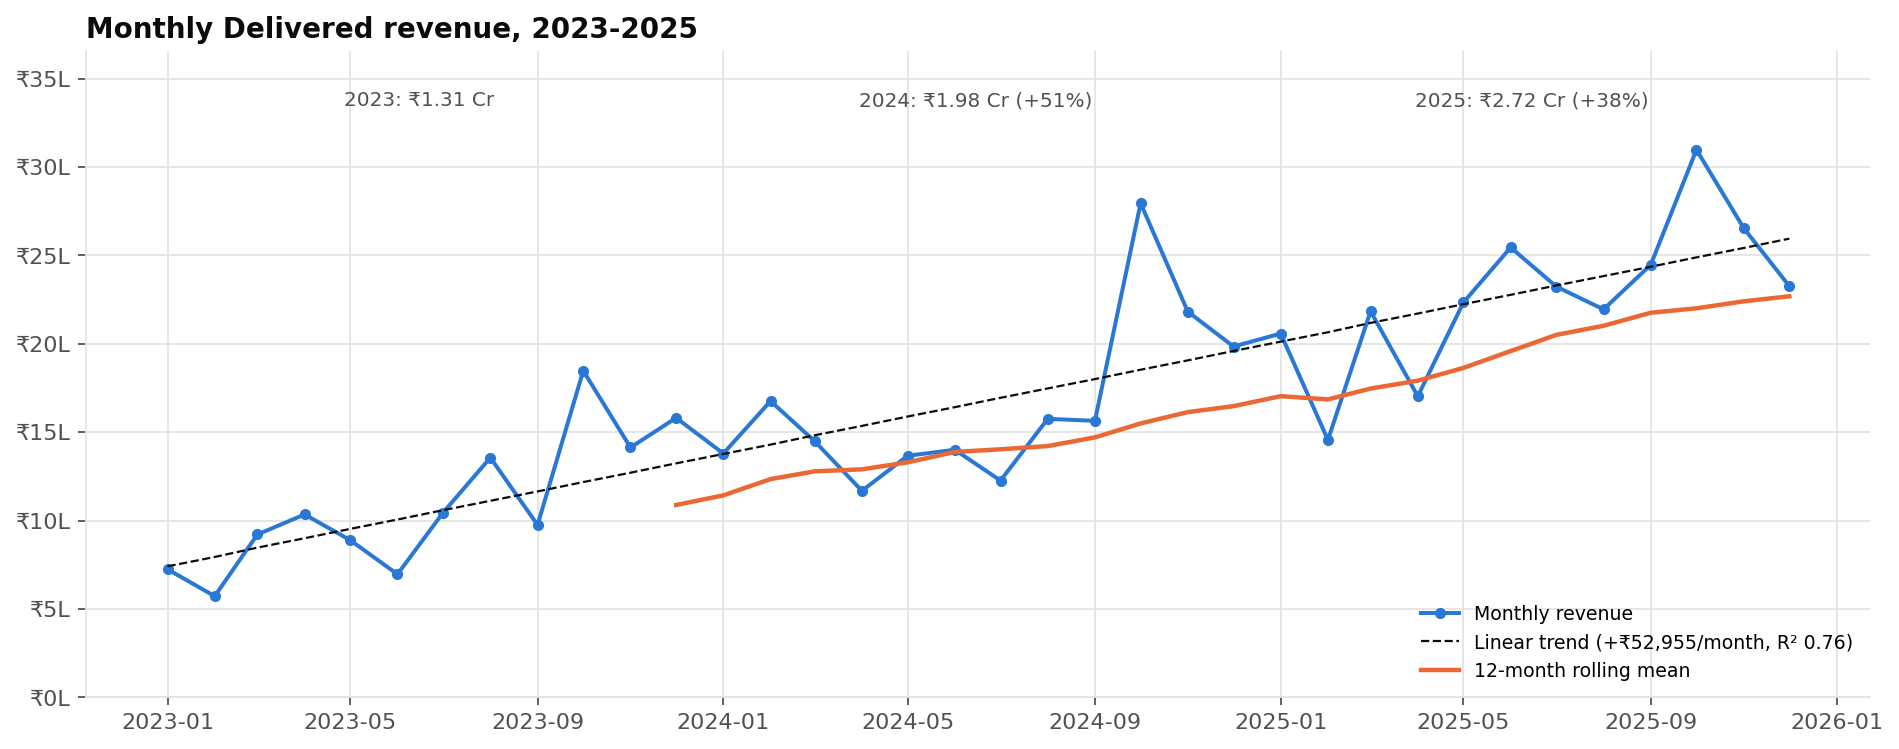

In [6]:
Image(str(FIG / "historical_revenue_trend.png"))

- **Rising trend:** about ₹53k more revenue per month (linear R² 0.76).
- **Annual growth:** +51% in 2024 and +38% in 2025, so growth is positive but slowing.

## 5. Seasonality

In [7]:
R['eda']['seasonal_index']

Year,Month_Number,2023,2024,2025,Mean_Index,Min_Index,Max_Index
0,1,0.67,0.84,0.91,0.80,0.67,0.91
1,2,0.53,1.02,0.64,0.73,0.53,1.02
2,3,0.85,0.88,0.96,0.90,0.85,0.96
3,4,0.95,0.71,0.75,0.80,0.71,0.95
4,5,0.82,0.83,0.98,0.88,0.82,0.98
5,6,0.64,0.85,1.12,0.87,0.64,1.12
6,7,0.96,0.74,1.02,0.91,0.74,1.02
7,8,1.25,0.96,0.97,1.06,0.96,1.25
8,9,0.90,0.95,1.08,0.97,0.90,1.08
9,10,1.70,1.70,1.37,1.59,1.37,1.70


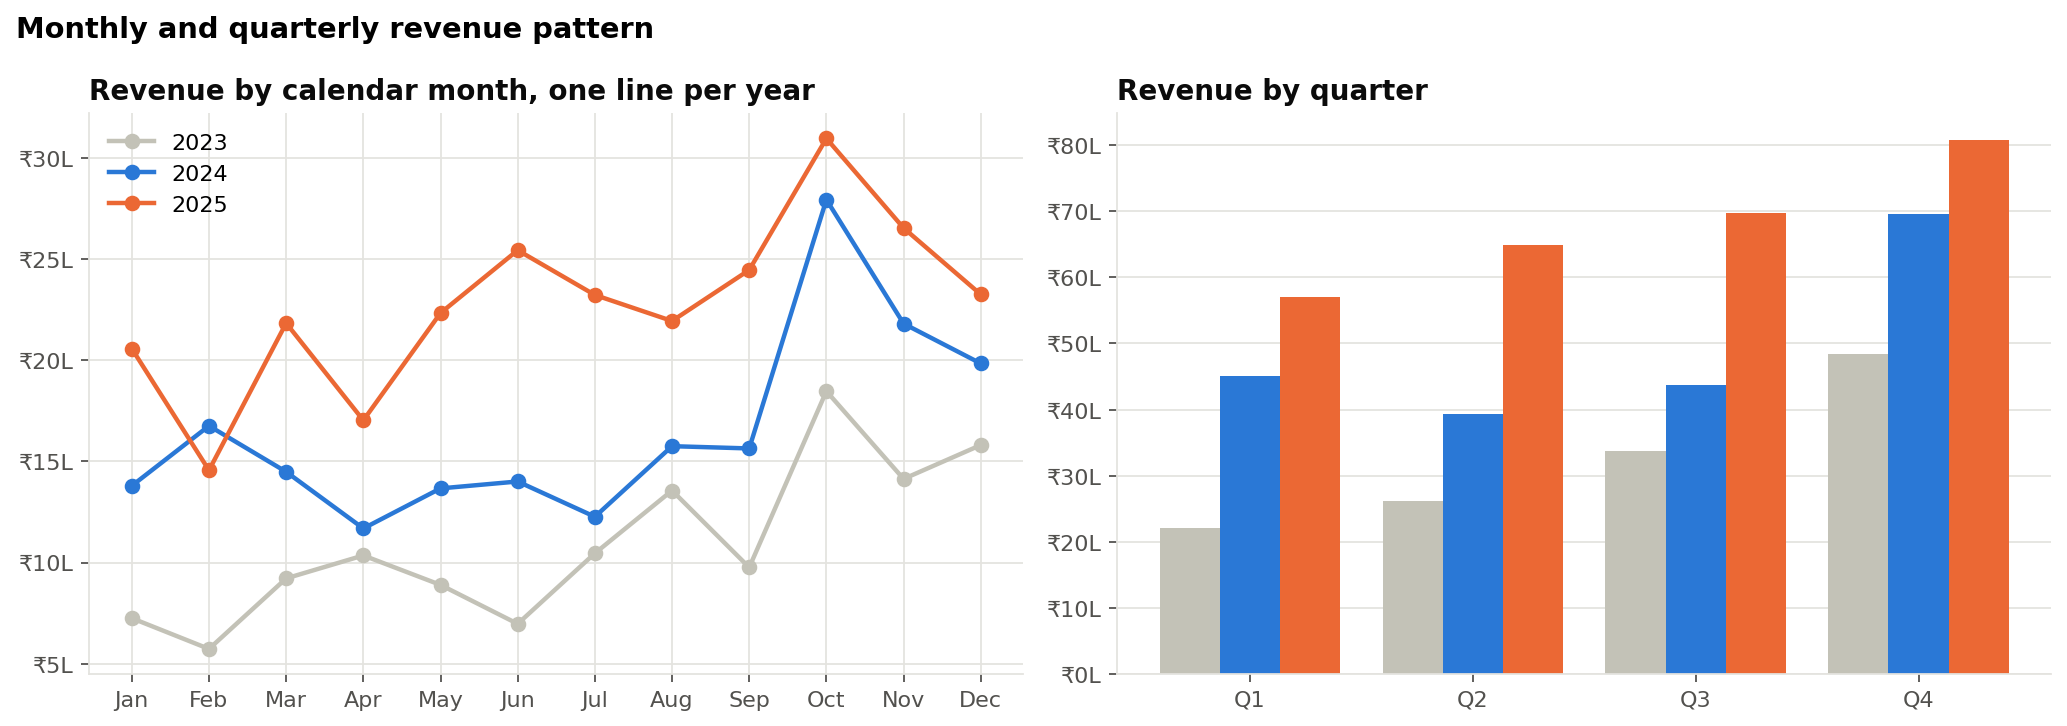

In [8]:
Image(str(FIG / "monthly_revenue_pattern.png"))

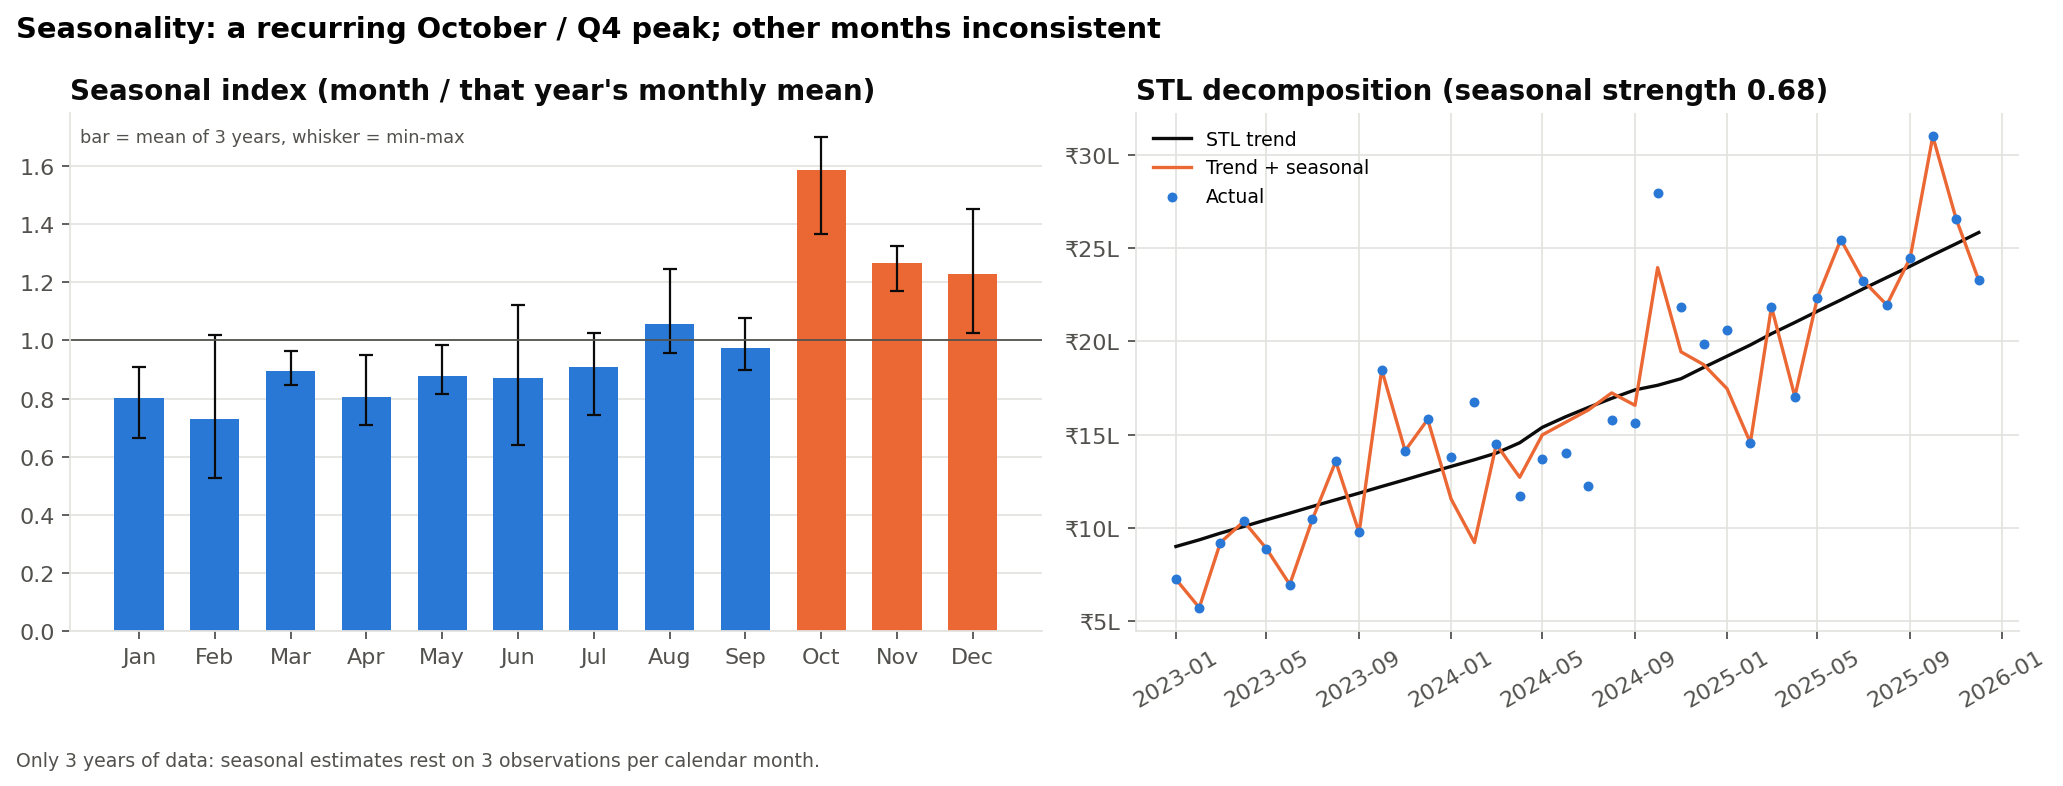

In [9]:
Image(str(FIG / "seasonal_pattern.png"))

- **October is the highest month in all three years** (index 1.70, 1.70, 1.37). November and December are also above average every year.
- **Other months are inconsistent.** February, for example, ranges from 0.53 to 1.02.
- **Conclusion:** there is a recurring Q4 (festive-season) peak. With only 3 observations per month, a detailed month-by-month profile is **not** claimed.

## 6. Volatility and distribution

In [10]:
R['eda']['decomposition'][R['eda']['decomposition']['Flag'] != '']

,Month,Revenue,STL_Trend,STL_Seasonal,STL_Residual,Residual_Z,Flag
13,2024-02-01,"1,676,214.25","1,365,230.81","-443,665.60","754,649.04",3.98,unusually high
18,2024-07-01,"1,226,548.40","1,645,371.47","-13,668.60","-405,154.47",-2.37,unusually low
21,2024-10-01,"2,795,219.00","1,764,269.55","630,406.54","400,542.91",2.04,unusually high


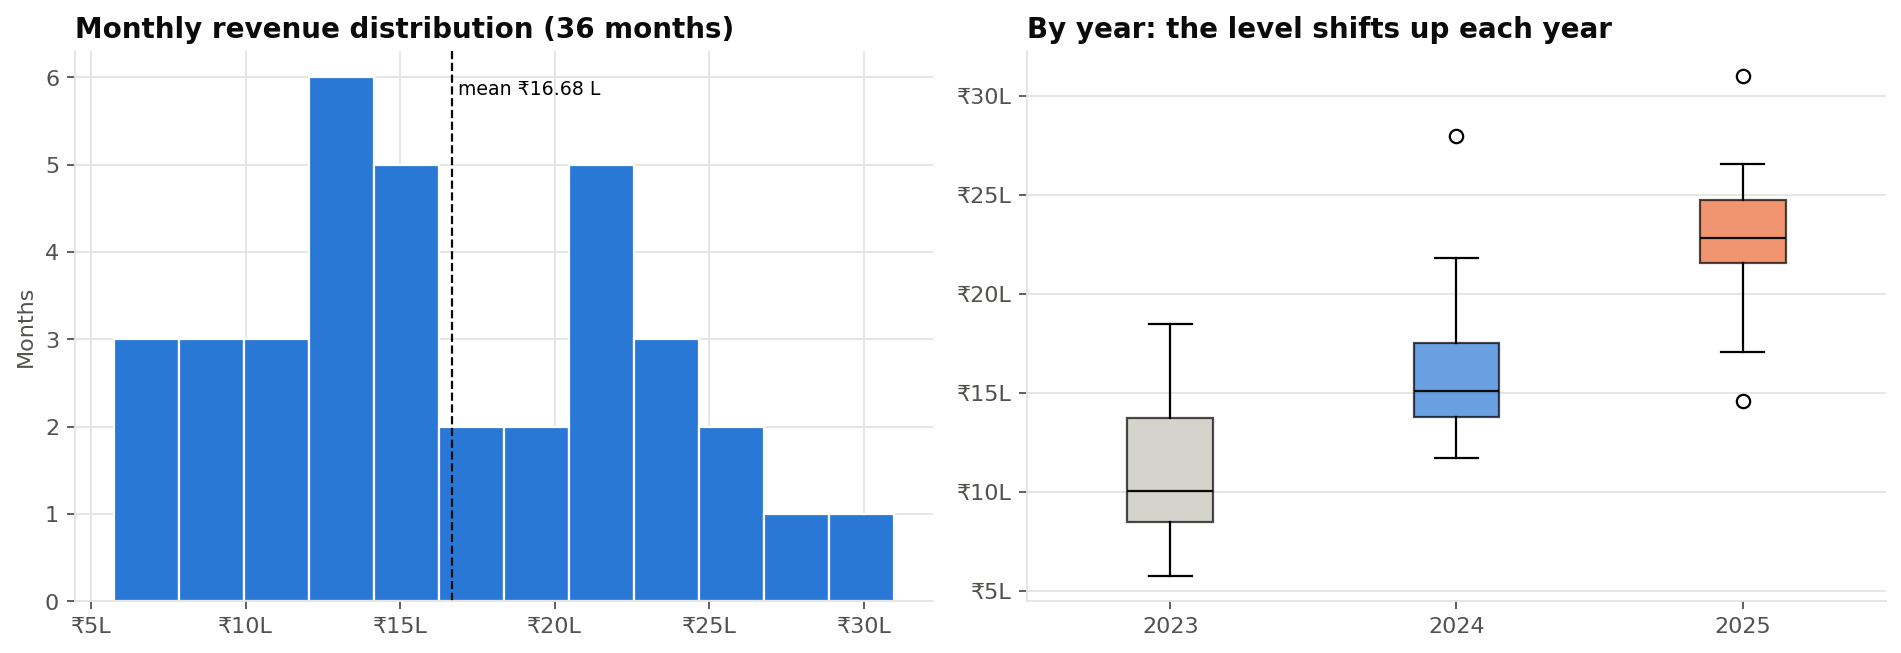

In [11]:
Image(str(FIG / "revenue_distribution.png"))

- **Month-to-month swings average 24%.**
- **Unusual months:** the STL residuals flag three, namely February 2024 and October 2024 (high) and July 2024 (low).

## 7. Rolling statistics

In [12]:
R['eda']['rolling'].tail(12)

,Month,Revenue,Rolling_Mean_3M,Rolling_Std_3M,Rolling_Mean_12M,Rolling_Std_12M,Rolling_CV_12M_%
24,2025-01-01,"2,058,026.15","2,074,903.73","99,612.61","1,704,007.30","471,478.98",27.67
25,2025-02-01,"1,456,402.75","1,833,079.00","328,259.00","1,685,689.67","476,895.82",28.29
26,2025-03-01,"2,184,197.40","1,899,542.10","388,920.50","1,746,971.06","490,738.22",28.09
27,2025-04-01,"1,703,556.80","1,781,385.65","370,086.83","1,791,546.65","456,533.32",25.48
28,2025-05-01,"2,234,210.00","2,040,654.73","293,004.40","1,863,830.04","451,814.50",24.24
29,2025-06-01,"2,544,999.00","2,160,921.93","425,481.61","1,959,164.45","465,754.78",23.77
30,2025-07-01,"2,323,566.20","2,367,591.73","160,003.55","2,050,582.60","413,628.92",20.17
31,2025-08-01,"2,194,859.35","2,354,474.85","177,104.35","2,102,181.75","386,746.49",18.40
32,2025-09-01,"2,447,160.20","2,321,861.92","126,159.06","2,175,740.16","358,054.85",16.46
33,2025-10-01,"3,097,837.75","2,579,952.43","465,905.39","2,200,958.39","412,212.92",18.73


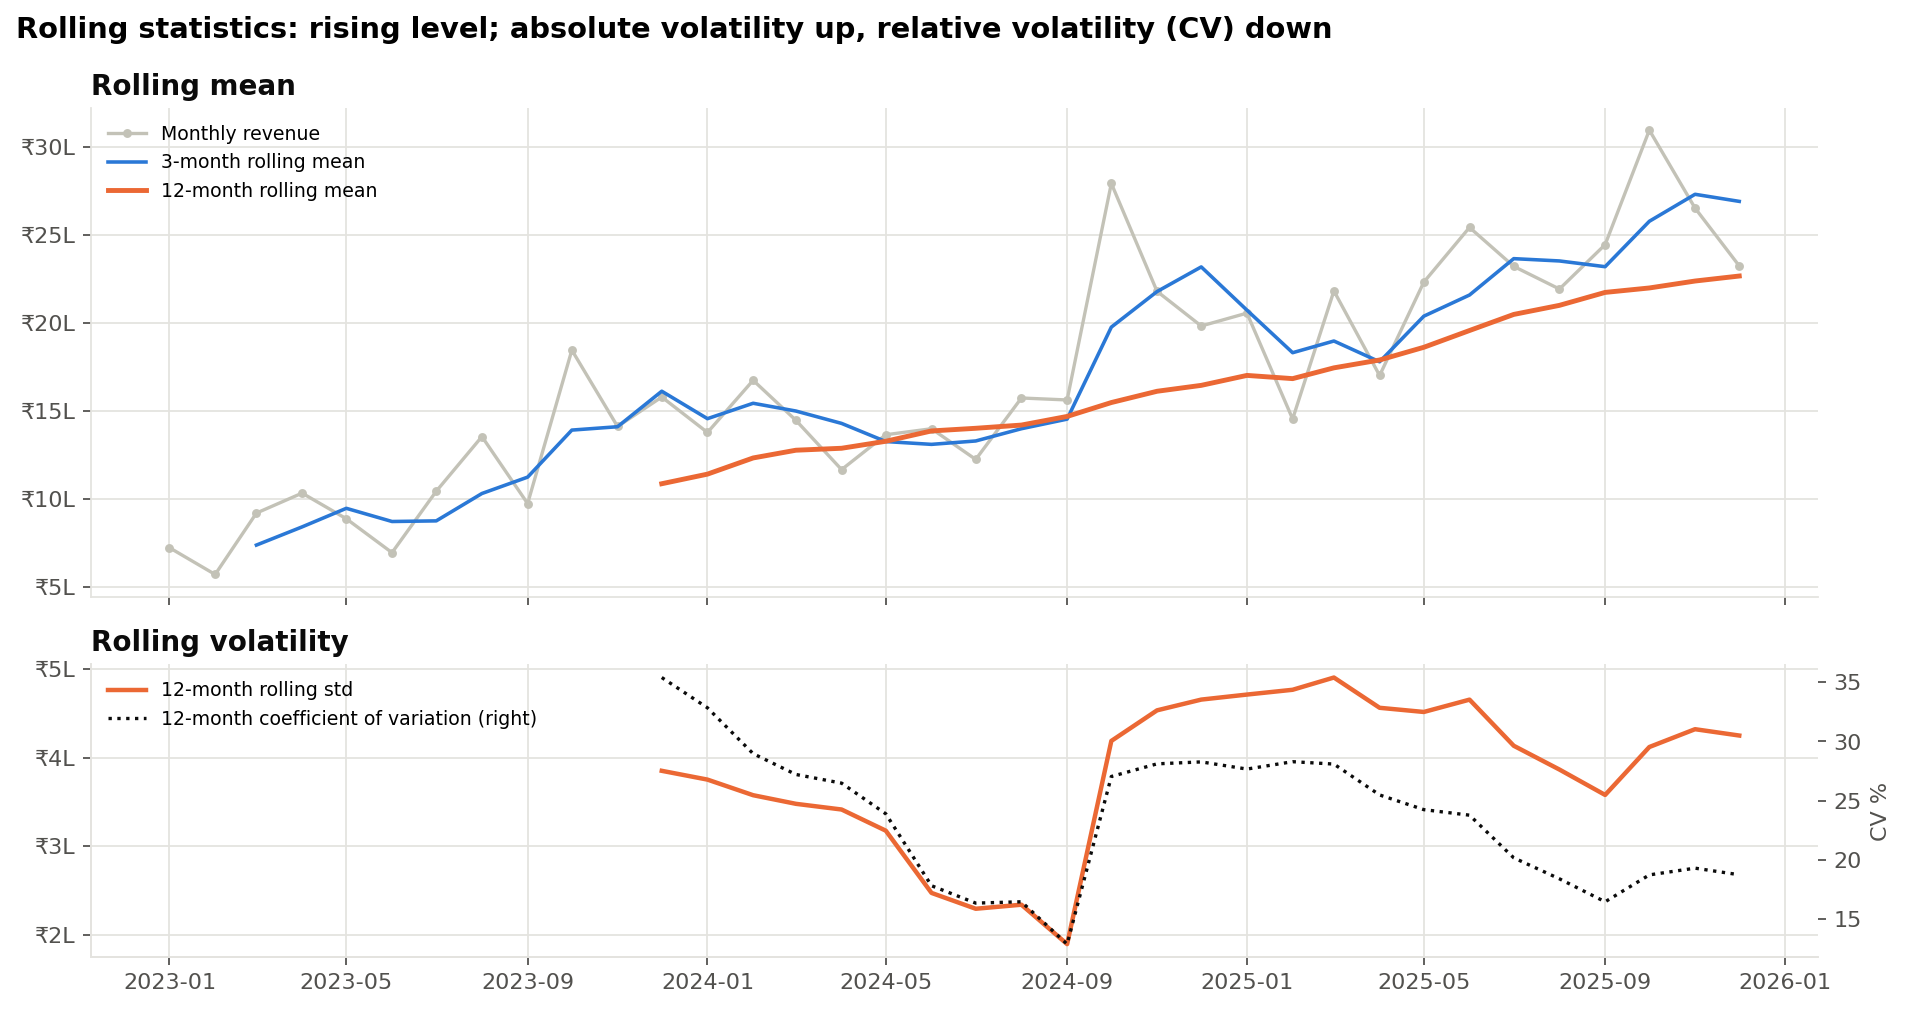

In [13]:
Image(str(FIG / "rolling_mean_std.png"))

- **Trend:** the 12-month rolling mean rises steadily, and this window removes the seasonal cycle.
- **Volatility:** the 12-month standard deviation is higher in 2024–2025 than in 2023, but relative volatility (CV) fell from about 35% to about 19%.
- **Stability:** the series is not stable in level, which is consistent with the stationarity tests in Section 8.

## 8. Stationarity (ADF) and autocorrelation

In [14]:
R['adf']

,Series,Observations,ADF_Statistic,p_value,Lags_Used,Critical_5%,Conclusion
0,Revenue (level),36,-2.21,0.20,0,-2.95,non-stationary (cannot reject unit root at 5%)
1,log(Revenue),36,-2.25,0.19,1,-2.95,non-stationary (cannot reject unit root at 5%)
2,First difference,35,-3.53,0.01,10,-2.99,stationary (reject unit root at 5%)
3,Seasonal difference (lag 12),24,-2.42,0.14,3,-3.02,non-stationary (cannot reject unit root at 5%)


In [15]:
R['acf']

,Lag,ACF_diff,PACF_diff,Approx_95%_Bound,ACF_Significant,PACF_Significant
0,0,1.00,1.00,0.33,True,True
1,1,-0.45,-0.45,0.33,True,True
2,2,0.06,-0.18,0.33,False,False
3,3,-0.06,-0.13,0.33,False,False
4,4,-0.09,-0.22,0.33,False,False
5,5,0.19,0.05,0.33,False,False
6,6,-0.37,-0.37,0.33,True,True
7,7,0.25,-0.15,0.33,False,False
8,8,-0.03,-0.05,0.33,False,False
9,9,-0.11,-0.26,0.33,False,False


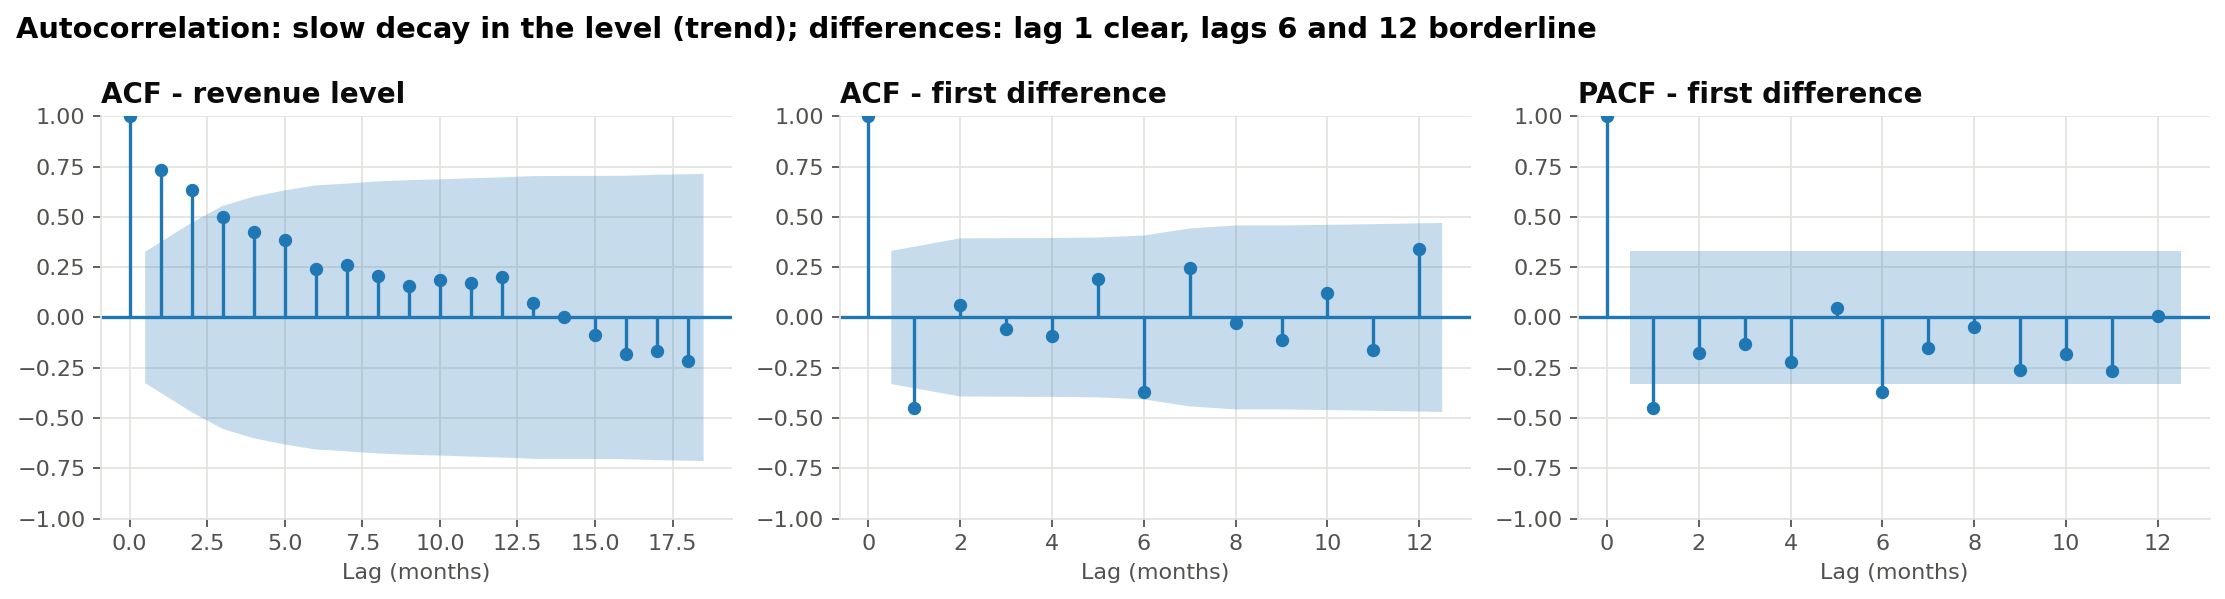

In [16]:
Image(str(FIG / "acf_pacf.png"))

- **Level:** non-stationary (p = 0.20).
- **First difference:** stationary (p = 0.007), so ARIMA uses **d = 1**.
- **Differenced series:** clear negative autocorrelation at lag 1; lags 6 and 12 are borderline.
- **What follows:** low-order AR/MA terms, with seasonal variants tested but kept minimal.
- **No log transform:** it does not change the result.

## 9. Chronological train / validation / test split

In [17]:
R['split']['summary']

,Split,Start,End,Months,Revenue
0,Train,2023-01,2024-12,24,"32,830,632.15"
1,Validation,2025-01,2025-06,6,"12,181,392.10"
2,Test,2025-07,2025-12,6,"15,044,544.90"


- **Split:** 24 / 6 / 6 months, in time order, never shuffled.
- **No leakage:**
  - validation forecasts are fitted on train only;
  - test forecasts are fitted on train + validation;
  - the future forecast is fitted on all 36 months.

## 10. Baselines, exponential smoothing, ARIMA/SARIMA and Theta

In [18]:
sp = R["split"]
demo = {
    "Naive": fc.naive_forecast(sp["train"], 6)["forecast"]["Forecast"],
    "Seasonal naive": fc.seasonal_naive_forecast(sp["train"], 6)["forecast"]["Forecast"],
    "Damped Holt": fc.exponential_smoothing_forecast(sp["train"], 6, "Damped Holt (A,Ad,N)")["forecast"]["Forecast"],
    "ARIMA(1,1,1)+drift": fc.arima_forecast(sp["train"], 6, "ARIMA(1,1,1) + drift")["forecast"]["Forecast"],
    "Theta": fc.theta_forecast(sp["train"], 6)["forecast"]["Forecast"],
}
pd.DataFrame(demo).assign(Actual=sp["valid"].values).round(0)

,Naive,Seasonal naive,Damped Holt,"ARIMA(1,1,1)+drift",Theta,Actual
2025-01-01,"1,984,808.00","1,379,694.00","1,987,619.00","2,031,513.00","2,131,992.00","2,058,026.00"
2025-02-01,"1,984,808.00","1,676,214.00","2,023,876.00","2,084,335.00","2,159,925.00","1,456,403.00"
2025-03-01,"1,984,808.00","1,448,821.00","2,058,878.00","2,138,640.00","2,187,858.00","2,184,197.00"
2025-04-01,"1,984,808.00","1,168,650.00","2,092,670.00","2,193,305.00","2,215,792.00","1,703,557.00"
2025-05-01,"1,984,808.00","1,366,809.00","2,125,293.00","2,248,058.00","2,243,725.00","2,234,210.00"
2025-06-01,"1,984,808.00","1,400,986.00","2,156,788.00","2,302,831.00","2,271,658.00","2,544,999.00"


In [19]:
R['tuning']

,Family,Specification,MAE,RMSE,MAPE_%,sMAPE_%,WAPE_%,Bias_%,AIC,Status,Best_in_Family
0,Naive,Naive (last month),"315,309.47","360,427.21",16.44,15.95,15.53,-2.24,NaN,ok,True
1,Seasonal naive,Seasonal naive (same month last year),"696,640.24","752,385.77",32.82,39.56,34.31,-30.70,NaN,ok,True
2,Exponential smoothing,"SES (A,N,N)","290,903.45","361,113.12",15.99,14.73,14.33,2.49,688.94,ok,False
3,Exponential smoothing,"Holt (A,A,N)","461,998.94","548,183.55",26.22,21.72,22.76,22.76,689.84,ok,False
4,Exponential smoothing,"Damped Holt (A,Ad,N)","274,906.81","330,824.13",15.18,14.00,13.54,2.17,687.77,ok,True
5,Exponential smoothing,"Holt-Winters additive (A,A,A)","345,851.81","414,315.65",17.24,17.42,17.04,-7.73,714.48,ok,False
6,Exponential smoothing,"Holt-Winters damped additive (A,Ad,A)","431,932.01","484,348.93",20.92,22.28,21.28,-13.79,719.77,ok,False
7,Exponential smoothing,"Holt-Winters multiplicative (A,Ad,M)","440,759.26","539,756.82",20.66,23.03,21.71,-15.86,687.01,ok,False
8,ARIMA / SARIMA,"ARIMA(0,1,1)","290,903.45","361,043.31",15.99,14.73,14.33,2.47,659.81,ok,False
9,ARIMA / SARIMA,"ARIMA(1,1,0)","292,197.67","354,482.75",15.73,14.80,14.39,0.75,659.25,ok,False


- **Candidates inside each model type** were compared on the validation months: 6 exponential-smoothing and 6 ARIMA/SARIMA variants.
- **Best of each type:**
  - Damped Holt (validation MAPE 15.2%);
  - ARIMA(1,1,1) with drift (14.2%);
  - Theta (15.6%).
- **Holt-Winters seasonal variants** did worse on validation (17–21%). This validation window (January–June) has no festive peak.
- **Development fix:** the drift terms originally went through SARIMAX, which created an upward-curving (quadratic) path. They were re-implemented with the ARIMA class.

## 11. Model evaluation

In [20]:
R['comparison']['table'].drop(columns=['Model'])

,Family,Specification,Val_MAE,Val_RMSE,Val_MAPE_%,Val_sMAPE_%,Val_WAPE_%,Val_Bias_%,Test_MAE,Test_RMSE,Test_MAPE_%,Test_sMAPE_%,Test_WAPE_%,Test_Bias_%,Test_95%_Interval_Coverage_%
0,Naive,Naive (last month),"315,309.47","360,427.21",16.44,15.95,15.53,-2.24,"258,480.72","301,872.13",10.14,10.10,10.31,1.50,100.00
1,Seasonal naive,Seasonal naive (same month last year),"696,640.24","752,385.77",32.82,39.56,34.31,-30.70,"619,327.28","682,872.74",25.63,30.72,24.70,-24.70,66.67
2,Exponential smoothing,"Damped Holt (A,Ad,N)","274,906.81","330,824.13",15.18,14.00,13.54,2.17,"273,434.32","396,364.92",9.82,10.85,10.90,-10.90,83.33
3,ARIMA / SARIMA,"ARIMA(1,1,1) + drift","240,961.15","340,531.00",14.23,12.44,11.87,6.71,"261,440.06","307,178.35",10.51,10.13,10.43,4.66,100.00
4,Theta,Theta (seasonality auto-tested),"262,706.59","373,634.91",15.55,13.42,12.94,8.45,"213,178.66","310,713.29",7.77,8.24,8.50,-4.65,100.00


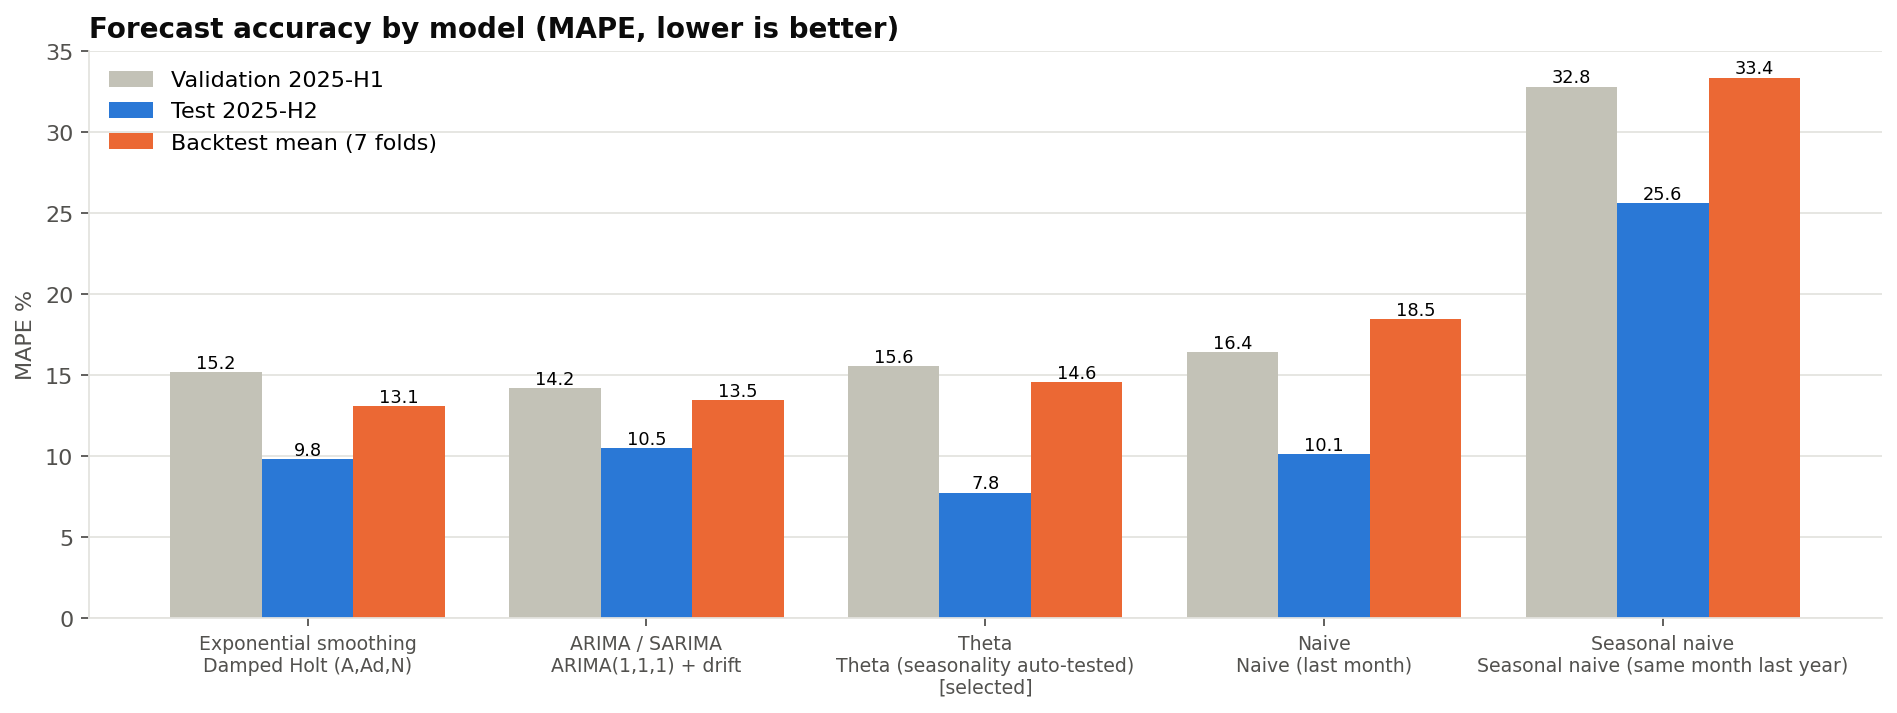

In [21]:
Image(str(FIG / "forecast_model_comparison.png"))

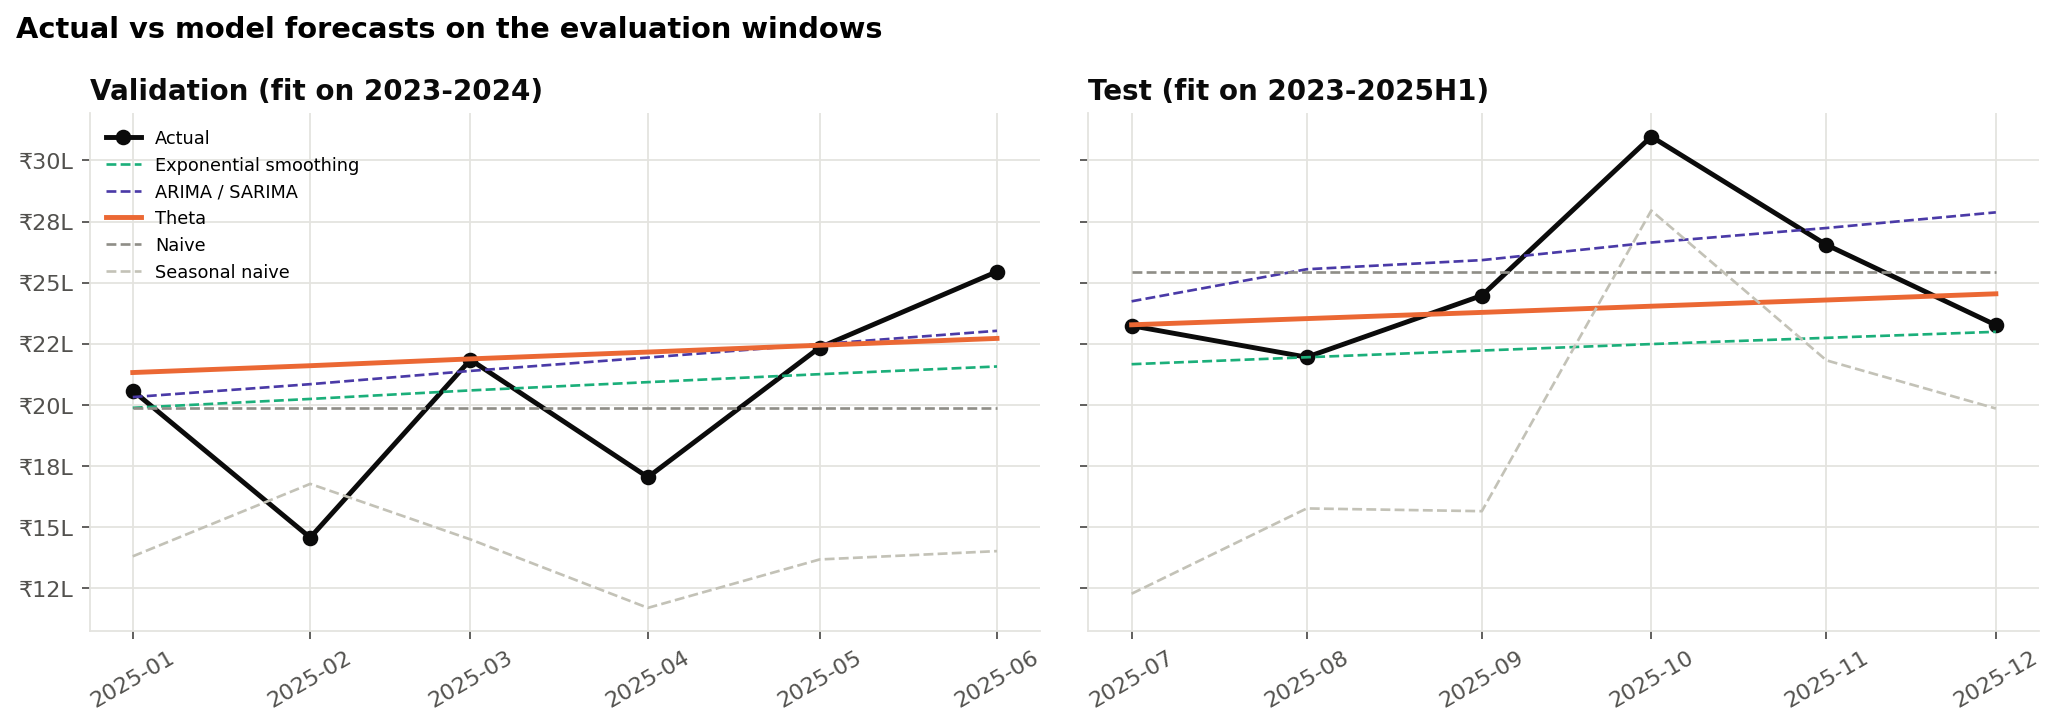

In [22]:
Image(str(FIG / "validation_test_forecasts.png"))

## 12. Backtesting

In [23]:
R['backtest']['summary']

,Family,Folds,Mean_MAE,Mean_RMSE,Mean_MAPE_pct,Std_MAPE_pct,Worst_MAPE_pct,Mean_WAPE_pct,Mean_Bias_pct,Folds_Won
0,Exponential smoothing,7,"299,376.50","366,300.49",13.11,2.36,15.46,13.00,-7.11,2
1,ARIMA / SARIMA,7,"299,471.79","377,939.00",13.47,3.62,17.77,13.02,-3.78,4
2,Theta,7,"329,036.20","403,119.53",14.56,3.84,19.92,14.27,-7.13,1
3,Naive,7,"422,932.28","477,931.60",18.47,9.38,32.73,18.46,-11.59,0
4,Seasonal naive,7,"763,546.37","814,161.34",33.38,4.22,37.78,33.55,-32.53,0


In [24]:
R['backtest']['folds'].pivot(index='Origin', columns='Family', values='MAPE_%').round(1)

Family,ARIMA / SARIMA,Exponential smoothing,Naive,Seasonal naive,Theta
Origin,,,,,
2024-12,14.20,15.20,16.40,32.80,15.60
2025-01,14.60,15.50,17.70,35.20,15.20
2025-02,17.80,11.30,32.70,37.40,16.60
2025-03,8.40,10.90,10.30,37.80,11.80
2025-04,17.70,14.40,30.20,34.20,19.90
2025-05,11.10,14.70,11.70,30.70,15.10
2025-06,10.50,9.80,10.10,25.60,7.80


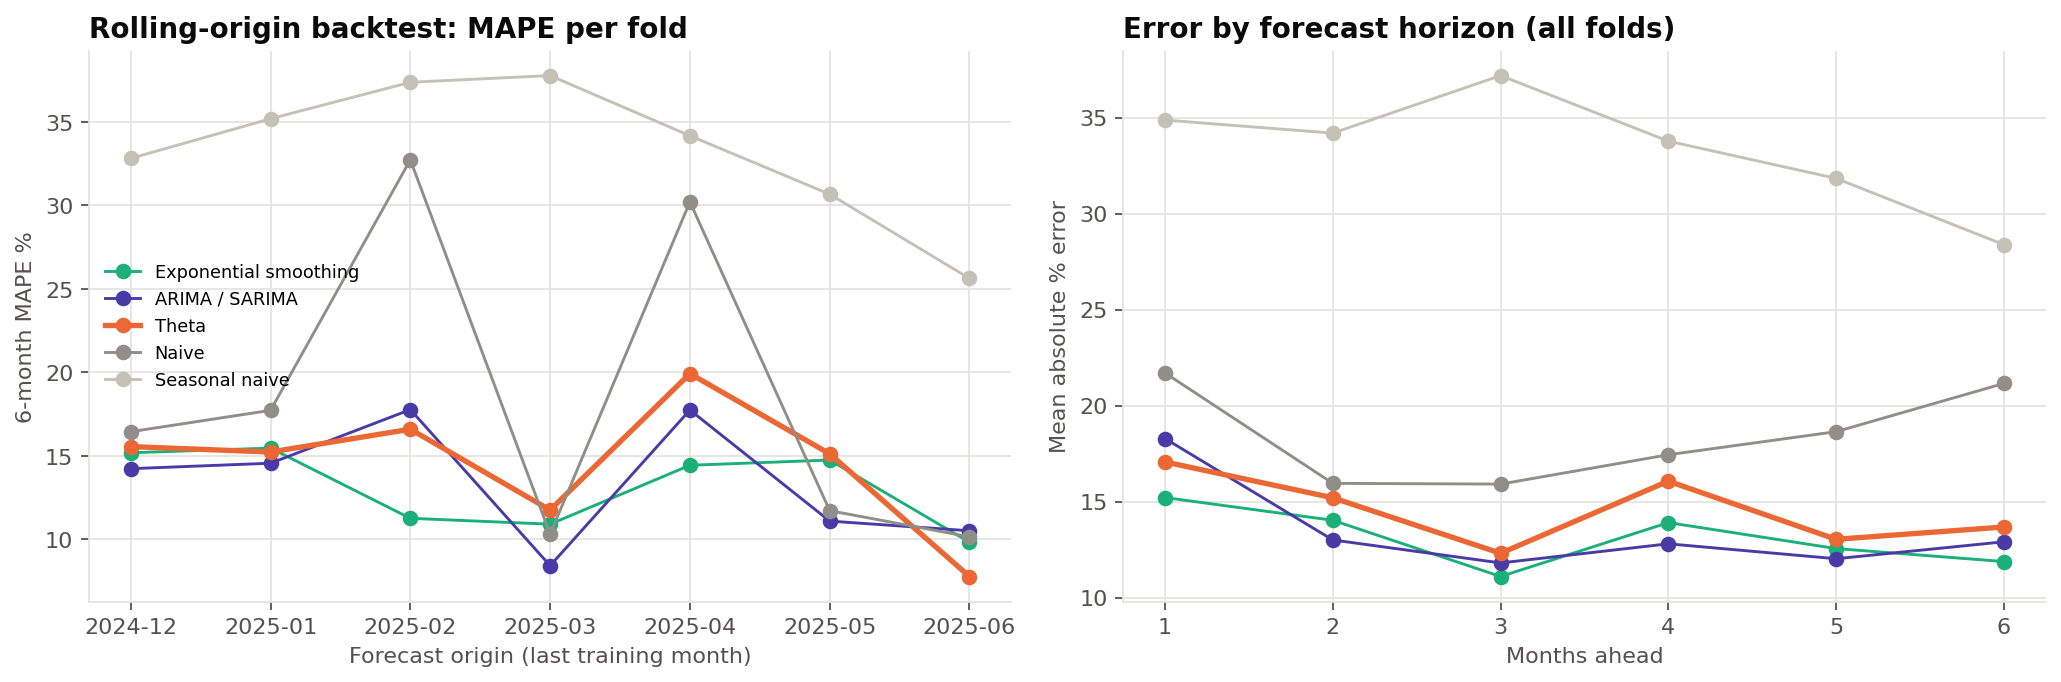

In [25]:
Image(str(FIG / "backtest_results.png"))

- **Why backtest:** two 6-month windows are too few to judge a model. So each model was refitted at 7 successive month-ends and forecast the next 6 months each time.
- **Results:**
  - the three non-baseline models average 13.1–14.6% MAPE;
  - naive averages 18.5% and swings a lot between folds (standard deviation 9.4);
  - seasonal naive averages 33.4%.
- **Caveat:** all folds fall in 2025.

## 13. Final model selection

In [26]:
R['selection']['table']

,Family,Mean_MAPE_pct,Std_MAPE_pct,Mean_MAE,Specification,Val_MAPE_%,Test_MAPE_%,Test_MAE,Beats_Both_Baselines_on_Test,Complexity,Within_5%_of_Best_Backtest_MAPE,Selected
0,Exponential smoothing,13.11,2.36,"299,376.50","Damped Holt (A,Ad,N)",15.18,9.82,"273,434.32",False,1,True,False
1,ARIMA / SARIMA,13.47,3.62,"299,471.79","ARIMA(1,1,1) + drift",14.23,10.51,"261,440.06",False,2,True,False
2,Theta,14.56,3.84,"329,036.20",Theta (seasonality auto-tested),15.55,7.77,"213,178.66",True,1,True,True
3,Naive,18.47,9.38,"422,932.28",Naive (last month),16.44,10.14,"258,480.72",True,0,False,False
4,Seasonal naive,33.38,4.22,"763,546.37",Seasonal naive (same month last year),32.82,25.63,"619,327.28",True,0,False,False


- **Rule (fixed before modelling):** lowest mean backtest MAPE among models that beat **both** baselines on test MAE.
- **What passed:** Damped Holt and ARIMA had slightly lower backtest MAPE but lost to naive on the test window. **Theta** was the only model that passed.
- **Theta's test results:** MAE ₹2.13L vs ₹2.58L for naive; MAPE 7.8%.
- **Seasonality:** its built-in test found no significant 12-month seasonality, so it forecasts level + trend only.
- **Caveat:** the margins between the top models are small.

## 14. Future revenue forecast

In [27]:
R['future']['forecast']

,Forecast,Lower_80,Upper_80,Lower_95,Upper_95
Month,,,,,
2026-01-01,"2,566,832.91","2,078,081.06","3,055,584.76","1,819,351.47","3,314,314.36"
2026-02-01,"2,593,310.31","1,856,391.09","3,330,229.53","1,466,289.61","3,720,331.00"
2026-03-01,"2,619,787.70","1,699,341.34","3,540,234.07","1,212,086.47","4,027,488.94"
2026-04-01,"2,646,265.10","1,573,235.24","3,719,294.96","1,005,207.54","4,287,322.65"
2026-05-01,"2,672,742.49","1,466,274.65","3,879,210.33","827,609.16","4,517,875.83"
2026-06-01,"2,699,219.89","1,372,669.39","4,025,770.39","670,435.98","4,728,003.80"


In [28]:
print("6-month total:", fc.inr(R["future"]["forecast"]["Forecast"].sum()))
a = joblib.load(ROOT / "models" / "forecasting_model.pkl")
print("Saved model reproduces the forecast:", np.allclose(a["fitted_model"].forecast(6), R["future"]["forecast"]["Forecast"]))

6-month total: ₹1.58 Cr
Saved model reproduces the forecast: True


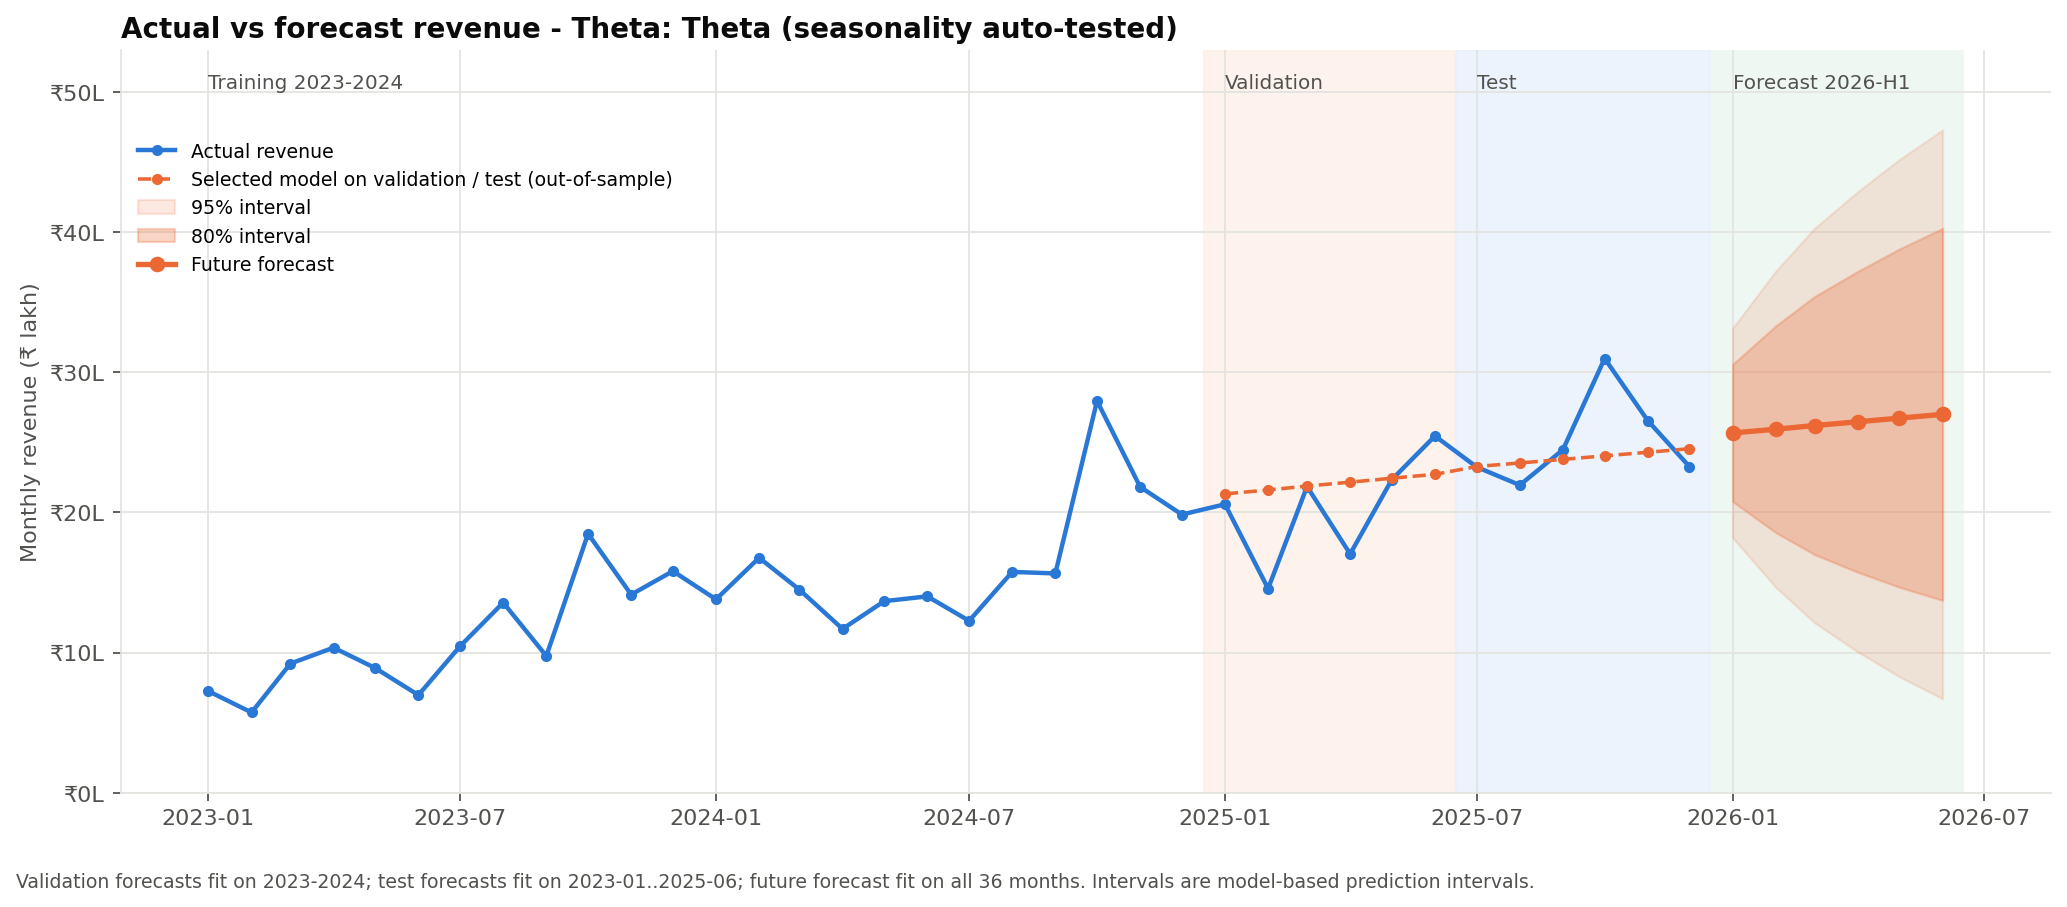

In [29]:
Image(str(FIG / "actual_vs_forecast.png"))

- **Total forecast for January–June 2026:** about ₹1.58 Cr, with 80% and 95% prediction intervals that widen over the horizon.
- **Interactive version:** `outputs/figures/forecasting/actual_vs_forecast_interactive.html` (Plotly, for later dashboard use).

## 15. Forecasting by business dimension

In [30]:
R['dimension']['evaluation']

,Dimension,Level,Monthly_Mean_Revenue,CV_%,Selected_Test_MAPE_%,Naive_Test_MAPE_%,Seasonal_Naive_Test_MAPE_%,Selected_Test_MAE,Naive_Test_MAE,Seasonal_Naive_Test_MAE,Published,Status
0,Category,Beauty,"94,498.98",41.26,12.87,14.76,23.89,"18,938.68","22,666.26","33,635.72",True,forecast published
1,Category,Books,"31,585.58",51.29,30.76,28.79,34.64,"15,333.39","14,246.43","16,919.27",False,not published: test MAPE > 20% or does not beat both baselines
2,Category,Electronics,"835,851.46",41.87,10.31,25.67,26.07,"140,792.74","299,495.97","323,697.47",True,forecast published
3,Category,Fashion,"334,937.25",41.24,13.86,17.68,30.93,"73,104.29","98,164.49","157,585.19",True,forecast published
4,Category,Home & Kitchen,"288,260.63",36.13,14.34,13.92,23.03,"50,089.97","51,053.55","86,410.08",True,forecast published
5,Category,Sports,"83,104.12",58.58,35.11,56.59,41.81,"58,545.49","88,218.98","61,196.98",False,not published: test MAPE > 20% or does not beat both baselines
6,Region,Central,"212,046.46",47.34,20.63,22.31,21.25,"70,415.88","70,484.50","82,615.96",False,not published: test MAPE > 20% or does not beat both baselines
7,Region,East,"206,644.42",50.04,25.13,28.59,37.01,"98,884.51","111,982.27","139,242.18",False,not published: test MAPE > 20% or does not beat both baselines
8,Region,North,"400,017.04",42.31,22.07,24.11,18.40,"111,630.36","117,560.78","100,760.64",False,not published: test MAPE > 20% or does not beat both baselines
9,Region,South,"450,720.51",41.33,15.33,15.85,28.92,"110,034.91","92,282.88","189,877.06",False,not published: test MAPE > 20% or does not beat both baselines


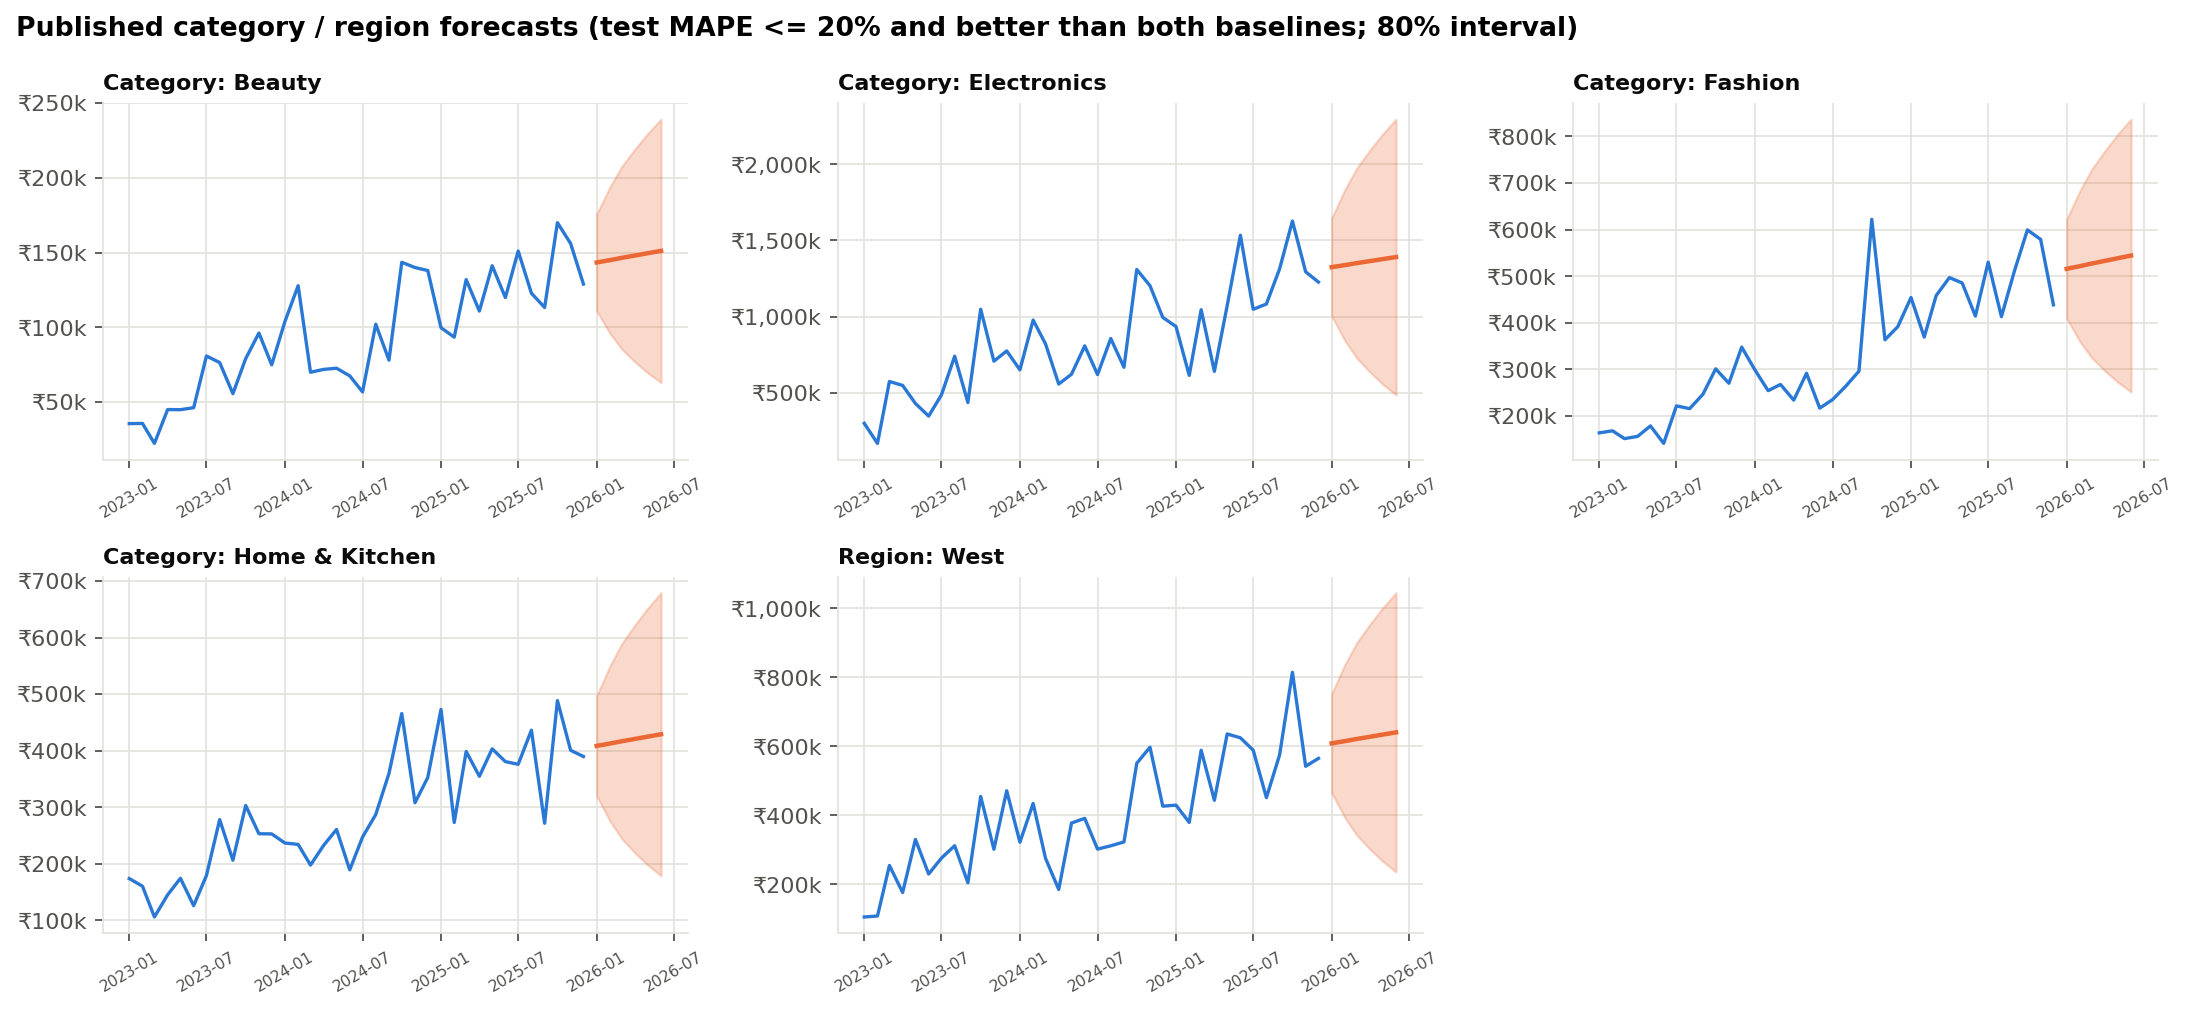

In [31]:
Image(str(FIG / "forecast_by_dimension.png"))

- **Rule for publishing a forecast:** it must have test MAPE ≤ 20% and beat both baselines on test MAE.
- **Published:** 4 categories (Beauty, Electronics, Fashion, Home & Kitchen) and the West region.
- **Not published:** Books, Sports and four regions, because their error is too high. Unreliable forecasts are deliberately withheld.

## 16. Business interpretation

In [32]:
R['insights']

,Area,Evidence,Planning interpretation
0,Revenue direction,Revenue grew 51% in 2024 and 38% in 2025; the 6-month forecast totals ₹1.58 Cr vs ₹1.22 Cr in the same months of 2025 (+30%).,"Plan for continued growth, but the forecast is a model extrapolation of 3 years of history."
1,Seasonality,"Highest month each year: 2023: month 10, 2024: month 10, 2025: month 10. Mean seasonal index for October 1.59 (range 1.37-1.70); Q4 shar...",A recurring Q4/October peak is supported; other month-to-month differences are not consistent across years.
2,Volatility,"Average absolute month-on-month change 24%; largest rise +89% (2023-10), largest fall -29% (2025-02).",Single-month targets need buffers; quarterly totals are more stable.
3,Forecast accuracy,"Selected model: backtest mean MAPE 14.6% (7 folds), test MAPE 7.8%.","Expect monthly errors of roughly this size; use the intervals, not only the point forecast."
4,Uncertainty,The 95% interval is on average 111% of the point forecast wide.,"Useful for cash-flow and inventory buffers: plan ranges, not single numbers."
5,Planning implications,Last 6 actual months ₹1.50 Cr vs previous 6 ₹1.22 Cr.,"Inventory, staffing and marketing budgets can be phased to the forecast path and to the Q4 peak; specific actions are for the recommenda..."


- **Growth:** growth continues (the forecast is +30% vs January–June 2025), but annual growth has been slowing.
- **Peak season:** plan inventory, staffing and marketing around the recurring October/Q4 peak.
- **Targets and cash flow:** use the intervals rather than single points. Month-to-month swings average 24%.
- **Horizon limit:** the forecast window excludes Q4. A 12-month plan needs a seasonal model and more history.

## 17. Quality-control checklist

In [33]:
R['qc']

,Check,Evidence,Pass
0,Actual cleaned dataset used,data/processed/customer_sales_cleaned.csv,True
1,Correct date handling (all dates parsed; monthly index regular),"36 months, freq=MS",True
2,Monthly aggregation reconciles with Delivered sales,₹6.01 Cr vs ₹6.01 Cr,True
3,No missing months (none filled with zero),0,True
4,No random split: train < validation < test in time,2024-12 < 2025-01; 2025-06 < 2025-07,True
5,No leakage: validation fits use train only; test fits use train+validation only; backtest fits use data before each origin,by construction (history slices),True
6,Baselines implemented,"Naive, Seasonal naive",True
7,Exponential smoothing tested,6 configurations,True
8,ARIMA / SARIMA tested,6 configurations,True
9,Stationarity checked (ADF),"level, log, first and seasonal differences",True
